# Flight Delay Prediction — Phase 1 (Machine Learning)

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from nycflights13 import flights

sns.set_style("whitegrid")
os.makedirs("figures", exist_ok=True)
RANDOM_STATE = 42

## 1. Load the data

In [2]:
df = flights.copy()
print("Shape:", df.shape)
df.head()

Shape: (336776, 19)


,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
0,2013,1,1,517.0,515,2.0,830.0,819,11.0,UA,1545,N14228,EWR,IAH,227.0,1400,5,15,2013-01-01T10:00:00Z
1,2013,1,1,533.0,529,4.0,850.0,830,20.0,UA,1714,N24211,LGA,IAH,227.0,1416,5,29,2013-01-01T10:00:00Z
2,2013,1,1,542.0,540,2.0,923.0,850,33.0,AA,1141,N619AA,JFK,MIA,160.0,1089,5,40,2013-01-01T10:00:00Z
3,2013,1,1,544.0,545,-1.0,1004.0,1022,-18.0,B6,725,N804JB,JFK,BQN,183.0,1576,5,45,2013-01-01T10:00:00Z
4,2013,1,1,554.0,600,-6.0,812.0,837,-25.0,DL,461,N668DN,LGA,ATL,116.0,762,6,0,2013-01-01T11:00:00Z


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 336776 entries, 0 to 336775
Data columns (total 19 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   year            336776 non-null  int64  
 1   month           336776 non-null  int64  
 2   day             336776 non-null  int64  
 3   dep_time        328521 non-null  float64
 4   sched_dep_time  336776 non-null  int64  
 5   dep_delay       328521 non-null  float64
 6   arr_time        328063 non-null  float64
 7   sched_arr_time  336776 non-null  int64  
 8   arr_delay       327346 non-null  float64
 9   carrier         336776 non-null  str    
 10  flight          336776 non-null  int64  
 11  tailnum         334264 non-null  str    
 12  origin          336776 non-null  str    
 13  dest            336776 non-null  str    
 14  air_time        327346 non-null  float64
 15  distance        336776 non-null  int64  
 16  hour            336776 non-null  int64  
 17  minute          33677

## 2. Data quality checks

In [4]:
missing = df.isna().sum()
print(missing[missing > 0])
print("\nDuplicate rows:", df.duplicated().sum())

dep_time     8255
dep_delay    8255
arr_time     8713
arr_delay    9430
tailnum      2512
air_time     9430
dtype: int64

Duplicate rows: 0


In [5]:
df = df.dropna(subset=["arr_delay"]).copy()

# Target: 1 if the flight arrived 15+ minutes late (the US Department of Transportation definition of "delayed")
df["delayed"] = (df["arr_delay"] >= 15).astype(int)

# A proper date column, used for EDA, features and the date-based split
df["date"] = pd.to_datetime(df[["year", "month", "day"]])

print("Flights left:", len(df))
print("Delayed share:", round(df["delayed"].mean(), 3))

Flights left: 327346
Delayed share: 0.245


## 3. Exploratory Data Analysis

### 3.1 Target balance and the distribution of arrival delays

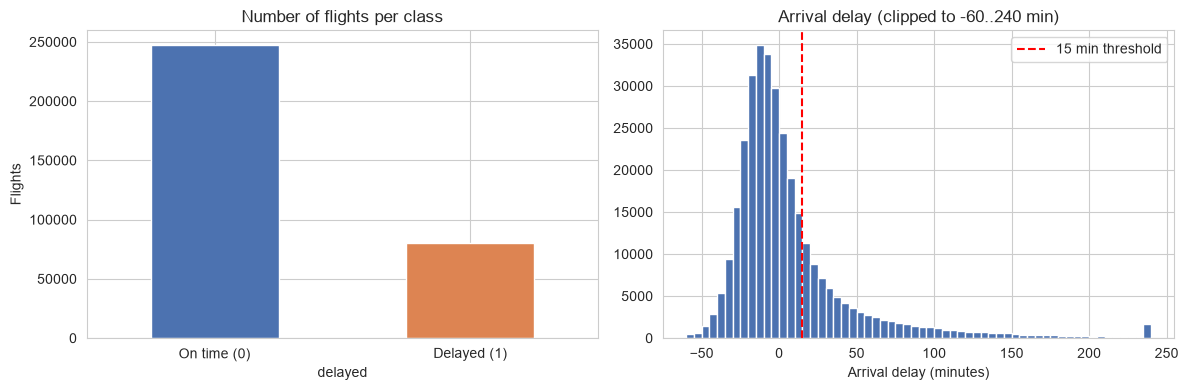

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df["delayed"].value_counts().sort_index().plot(kind="bar", ax=axes[0], color=["#4C72B0", "#DD8452"])
axes[0].set_xticks([0, 1], ["On time (0)", "Delayed (1)"], rotation=0)
axes[0].set_title("Number of flights per class")
axes[0].set_ylabel("Flights")

axes[1].hist(df["arr_delay"].clip(-60, 240), bins=60, color="#4C72B0")
axes[1].axvline(15, color="red", linestyle="--", label="15 min threshold")
axes[1].set_title("Arrival delay (clipped to -60..240 min)")
axes[1].set_xlabel("Arrival delay (minutes)")
axes[1].legend()

plt.tight_layout()
plt.savefig("figures/target_distribution.png", dpi=150)
plt.show()

### 3.2 Delay rate by month, weekday and hour

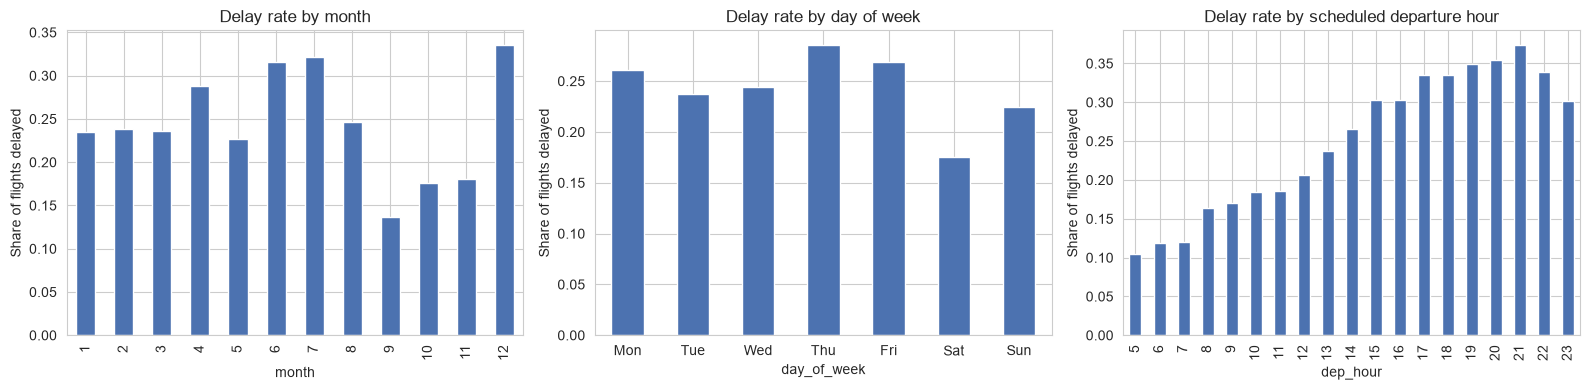

In [7]:
df["day_of_week"] = df["date"].dt.dayofweek   # 0 = Monday
df["dep_hour"] = df["sched_dep_time"] // 100

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
df.groupby("month")["delayed"].mean().plot(kind="bar", ax=axes[0], color="#4C72B0")
axes[0].set_title("Delay rate by month")
df.groupby("day_of_week")["delayed"].mean().plot(kind="bar", ax=axes[1], color="#4C72B0")
axes[1].set_xticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], rotation=0)
axes[1].set_title("Delay rate by day of week")
df.groupby("dep_hour")["delayed"].mean().plot(kind="bar", ax=axes[2], color="#4C72B0")
axes[2].set_title("Delay rate by scheduled departure hour")
for ax in axes:
    ax.set_ylabel("Share of flights delayed")

plt.tight_layout()
plt.savefig("figures/delay_by_time.png", dpi=150)
plt.show()

### 3.3 Delay rate by carrier and origin airport

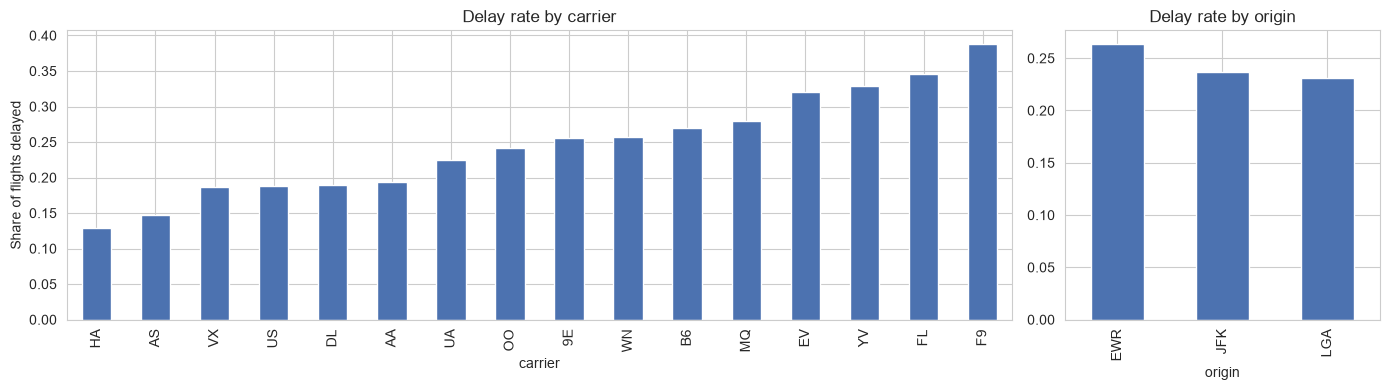

,delay_rate,flights
carrier,,
HA,0.129,342
AS,0.147,709
VX,0.187,5116
US,0.188,19831
DL,0.190,47658
AA,0.194,31947
UA,0.225,57782
OO,0.241,29
9E,0.256,17294


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [3, 1]})

carrier_stats = df.groupby("carrier")["delayed"].agg(["mean", "size"]).sort_values("mean")
carrier_stats["mean"].plot(kind="bar", ax=axes[0], color="#4C72B0")
axes[0].set_title("Delay rate by carrier")
axes[0].set_ylabel("Share of flights delayed")

df.groupby("origin")["delayed"].mean().plot(kind="bar", ax=axes[1], color="#4C72B0")
axes[1].set_title("Delay rate by origin")

plt.tight_layout()
plt.savefig("figures/delay_by_carrier_origin.png", dpi=150)
plt.show()

carrier_stats.rename(columns={"mean": "delay_rate", "size": "flights"}).round(3)

## 4. Removing data leakage

In [9]:
leaky_columns = ["dep_time", "dep_delay", "arr_time", "arr_delay", "air_time"]
other_dropped = ["tailnum", "flight", "time_hour", "year", "day", "hour", "minute"]

df = df.drop(columns=leaky_columns + other_dropped)
df.columns.tolist()

['month',
 'sched_dep_time',
 'sched_arr_time',
 'carrier',
 'origin',
 'dest',
 'distance',
 'delayed',
 'date',
 'day_of_week',
 'dep_hour']

## 5. Feature engineering

### 5.1 Calendar and schedule features (with cyclic time encoding)

In [10]:
df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)
df["arr_hour"] = df["sched_arr_time"] // 100

# Cyclic encoding: hour 23 is next to hour 0 and Sunday is next to Monday,
# so each time value is placed on a circle using sine and cosine
df["dep_hour_sin"] = np.sin(2 * np.pi * df["dep_hour"] / 24)
df["dep_hour_cos"] = np.cos(2 * np.pi * df["dep_hour"] / 24)
df["arr_hour_sin"] = np.sin(2 * np.pi * df["arr_hour"] / 24)
df["arr_hour_cos"] = np.cos(2 * np.pi * df["arr_hour"] / 24)
df["day_of_week_sin"] = np.sin(2 * np.pi * df["day_of_week"] / 7)
df["day_of_week_cos"] = np.cos(2 * np.pi * df["day_of_week"] / 7)

df[["dep_hour", "dep_hour_sin", "dep_hour_cos"]].drop_duplicates().sort_values("dep_hour").head()

,dep_hour,dep_hour_sin,dep_hour_cos
0,5,0.965926,2.588190e-01
4,6,1.000000,6.123234e-17
53,7,0.965926,-2.588190e-01
103,8,0.866025,-5.000000e-01
159,9,0.707107,-7.071068e-01


### 5.2 Airport congestion features

In [11]:
schedule = flights.copy()
schedule["date"] = pd.to_datetime(schedule[["year", "month", "day"]])
schedule["dep_hour"] = schedule["sched_dep_time"] // 100

hour_counts = schedule.groupby(["date", "origin", "dep_hour"]).size().rename("origin_hour_flights")
day_counts = schedule.groupby(["date", "origin"]).size().rename("origin_day_flights")

df = df.join(hour_counts, on=["date", "origin", "dep_hour"]).join(day_counts, on=["date", "origin"])

df[["origin_hour_flights", "origin_day_flights"]].describe().round(1)

,origin_hour_flights,origin_day_flights
count,327346.0,327346.0
mean,20.5,312.6
std,5.9,36.6
min,1.0,171.0
25%,17.0,297.0
50%,21.0,313.0
75%,24.0,340.0
max,38.0,377.0


### 5.3 Historical delay features

In [12]:
def add_past_delay_rate(df, col, window=7):
    """Share of delayed flights for each value of `col` over the previous `window` days (today excluded)."""
    delayed_per_day = df.pivot_table(index="date", columns=col, values="delayed", aggfunc="sum", fill_value=0)
    flights_per_day = df.pivot_table(index="date", columns=col, values="delayed", aggfunc="count", fill_value=0)

    past_delayed = delayed_per_day.rolling(window, min_periods=1).sum().shift(1)
    past_flights = flights_per_day.rolling(window, min_periods=1).sum().shift(1)
    rate = past_delayed / past_flights.replace(0, np.nan)   # NaN if there were no flights in the window

    new_col = f"{col}_delay_rate_7d"
    rate = rate.stack().rename(new_col).reset_index()
    return df.merge(rate, on=["date", col], how="left")

# Route = origin and destination together, e.g. "JFK-LAX"
df["route"] = df["origin"] + "-" + df["dest"]

for col in ["carrier", "origin", "dest", "route"]:
    df = add_past_delay_rate(df, col)

df[["date", "carrier", "carrier_delay_rate_7d", "origin_delay_rate_7d", "dest_delay_rate_7d", "route_delay_rate_7d"]].head()

,date,carrier,carrier_delay_rate_7d,origin_delay_rate_7d,dest_delay_rate_7d,route_delay_rate_7d
0,2013-01-01,UA,NaN,NaN,NaN,NaN
1,2013-01-01,UA,NaN,NaN,NaN,NaN
2,2013-01-01,AA,NaN,NaN,NaN,NaN
3,2013-01-01,B6,NaN,NaN,NaN,NaN
4,2013-01-01,DL,NaN,NaN,NaN,NaN


In [13]:
# Final feature list
numeric_features = ["is_weekend", "day_of_week_sin", "day_of_week_cos",
                    "dep_hour_sin", "dep_hour_cos", "arr_hour_sin", "arr_hour_cos", "distance",
                    "origin_hour_flights", "origin_day_flights",
                    "carrier_delay_rate_7d", "origin_delay_rate_7d", "dest_delay_rate_7d", "route_delay_rate_7d"]
categorical_features = ["carrier", "origin", "dest"]

# Sanity check: no leaky column is used as a feature
assert not set(leaky_columns) & set(numeric_features + categorical_features)

df[numeric_features].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
is_weekend,327346.0,0.25,0.44,0.00,0.00,0.00,1.00,1.00
day_of_week_sin,327346.0,0.04,0.69,-0.97,-0.78,0.00,0.78,0.97
day_of_week_cos,327346.0,0.01,0.72,-0.90,-0.90,-0.22,0.62,1.00
dep_hour_sin,327346.0,-0.12,0.77,-1.00,-0.87,-0.26,0.71,1.00
dep_hour_cos,327346.0,-0.39,0.50,-1.00,-0.87,-0.50,-0.00,0.97
arr_hour_sin,327346.0,-0.31,0.63,-1.00,-0.87,-0.50,0.26,1.00
arr_hour_cos,327346.0,-0.24,0.67,-1.00,-0.87,-0.50,0.50,1.00
distance,327346.0,1048.37,735.91,80.00,509.00,888.00,1389.00,4983.00
origin_hour_flights,327346.0,20.50,5.93,1.00,17.00,21.00,24.00,38.00
origin_day_flights,327346.0,312.64,36.58,171.00,297.00,313.00,340.00,377.00


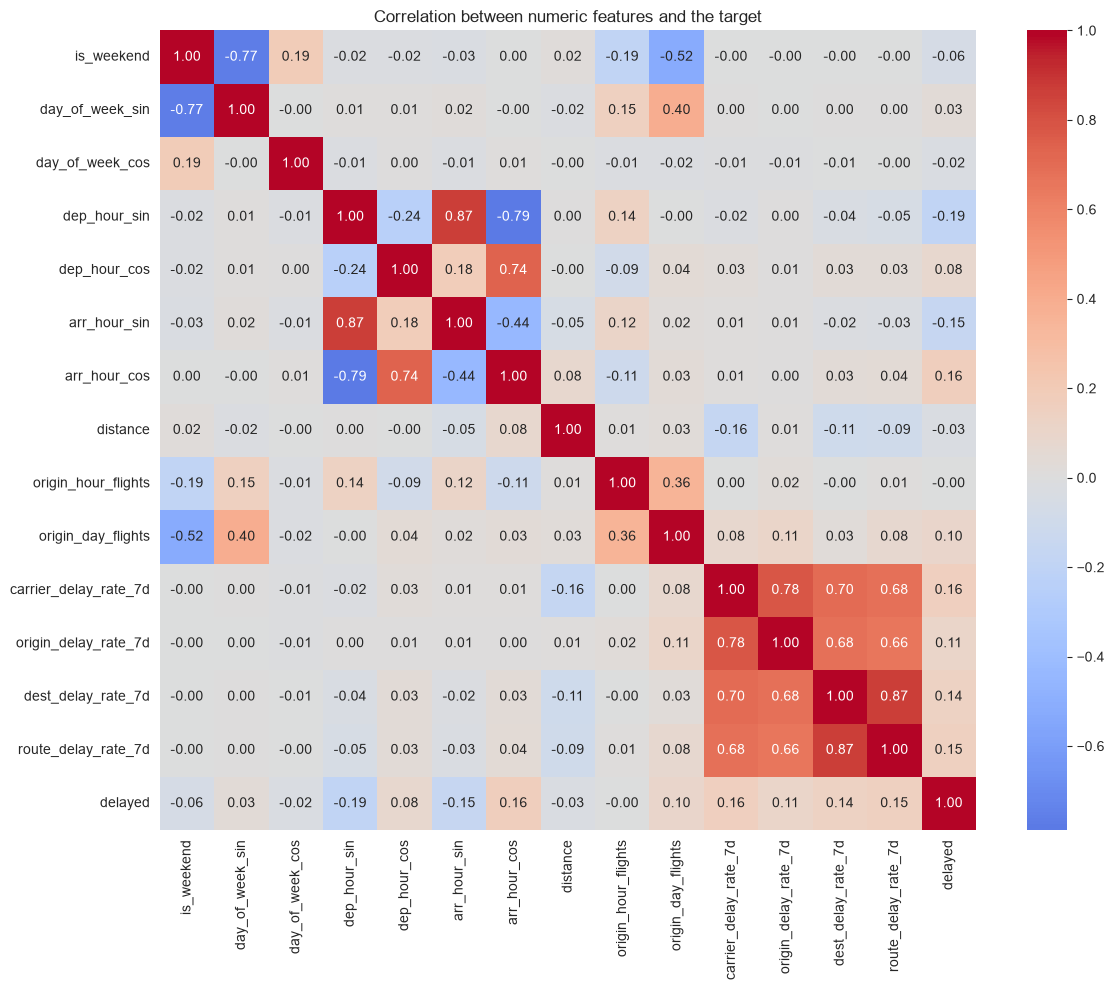

In [14]:
corr = df[numeric_features + ["delayed"]].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between numeric features and the target")
plt.tight_layout()
plt.savefig("figures/correlation.png", dpi=150)
plt.show()

## 6. Train / validation / test split by date

In [15]:
train = df[df["month"] <= 8]
val = df[df["month"].isin([9, 10])]
test = df[df["month"] >= 11]

# Sanity check: the sets do not overlap in time
assert train["date"].max() < val["date"].min() and val["date"].max() < test["date"].min()

pd.DataFrame({
    "flights": [len(train), len(val), len(test)],
    "delayed_share": [train["delayed"].mean(), val["delayed"].mean(), test["delayed"].mean()],
}, index=["train", "validation", "test"]).round(3)

,flights,delayed_share
train,217727,0.264
validation,55628,0.157
test,53991,0.258


In [16]:
def make_features(data):
    X = pd.get_dummies(data[numeric_features + categorical_features], columns=categorical_features, dtype=int)
    return X

X_train = make_features(train)
# Validation/test must have exactly the same columns as training (unseen destinations become all zeros)
X_val = make_features(val).reindex(columns=X_train.columns, fill_value=0)
X_test = make_features(test).reindex(columns=X_train.columns, fill_value=0)

# Fill missing history values with the training average
history_cols = ["carrier_delay_rate_7d", "origin_delay_rate_7d", "dest_delay_rate_7d", "route_delay_rate_7d"]
train_means = X_train[history_cols].mean()
X_train = X_train.fillna(train_means)
X_val = X_val.fillna(train_means)
X_test = X_test.fillna(train_means)

y_train, y_val, y_test = train["delayed"], val["delayed"], test["delayed"]

print("X_train:", X_train.shape, " X_val:", X_val.shape, " X_test:", X_test.shape)

X_train: (217727, 135)  X_val: (55628, 135)  X_test: (53991, 135)


## 7. Models

### 7.1 Logistic Regression (baseline)

In [17]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score

log_reg = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=1000),
)
log_reg.fit(X_train, y_train)

val_prob_lr = log_reg.predict_proba(X_val)[:, 1]
print("Logistic Regression - validation PR AUC:", round(average_precision_score(y_val, val_prob_lr), 4))
print("Logistic Regression - validation ROC AUC:", round(roc_auc_score(y_val, val_prob_lr), 4))

Logistic Regression - validation PR AUC: 0.2618
Logistic Regression - validation ROC AUC: 0.663


### 7.2 XGBoost

In [18]:
from xgboost import XGBClassifier

# Train + validation together, so we can cut them into time-ordered folds
X_dev = pd.concat([X_train, X_val])
y_dev = pd.concat([y_train, y_val])
month_dev = pd.concat([train["month"], val["month"]])
folds = [(4, [5, 6]), (6, [7, 8]), (8, [9, 10])]   # (last training month, validation months)

def make_xgb(depth, n_trees, y):
    return XGBClassifier(
        n_estimators=n_trees,
        learning_rate=0.05,
        max_depth=depth,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=50,
        scale_pos_weight=(y == 0).sum() / (y == 1).sum(),
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )

results = []
for depth in [3, 4, 6]:
    for n_trees in [100, 300]:
        scores = []
        for last_month, val_months in folds:
            fit_rows = (month_dev <= last_month).values
            val_rows = month_dev.isin(val_months).values
            model = make_xgb(depth, n_trees, y_dev[fit_rows]).fit(X_dev[fit_rows], y_dev[fit_rows])
            scores.append(average_precision_score(y_dev[val_rows], model.predict_proba(X_dev[val_rows])[:, 1]))
        results.append({"max_depth": depth, "n_trees": n_trees,
                        "fold1": scores[0], "fold2": scores[1], "fold3": scores[2], "mean_PR_AUC": np.mean(scores)})

cv_results = pd.DataFrame(results).round(4).sort_values("mean_PR_AUC", ascending=False)
cv_results

,max_depth,n_trees,fold1,fold2,fold3,mean_PR_AUC
0,3,100,0.4240,0.4450,0.2624,0.3771
2,4,100,0.4211,0.4457,0.2614,0.3761
4,6,100,0.4229,0.4575,0.2469,0.3758
1,3,300,0.4083,0.4467,0.2545,0.3699
3,4,300,0.4120,0.4489,0.2461,0.3690
5,6,300,0.4184,0.4517,0.2311,0.3671


In [19]:
best = cv_results.iloc[0]
print("Best settings: max_depth =", int(best["max_depth"]), " n_trees =", int(best["n_trees"]))

xgb = make_xgb(int(best["max_depth"]), int(best["n_trees"]), y_train).fit(X_train, y_train)

val_prob_xgb = xgb.predict_proba(X_val)[:, 1]
print("XGBoost - validation PR AUC:", round(average_precision_score(y_val, val_prob_xgb), 4))
print("XGBoost - validation ROC AUC:", round(roc_auc_score(y_val, val_prob_xgb), 4))

Best settings: max_depth = 3  n_trees = 100


XGBoost - validation PR AUC: 0.2624
XGBoost - validation ROC AUC: 0.6648


## 8. Evaluation on the test set

In [20]:
from sklearn.metrics import precision_recall_curve, roc_curve, brier_score_loss

test_prob_lr = log_reg.predict_proba(X_test)[:, 1]
test_prob_xgb = xgb.predict_proba(X_test)[:, 1]

def recall_at_precision(y_true, prob, min_precision=0.5):
    precision, recall, _ = precision_recall_curve(y_true, prob)
    return recall[precision >= min_precision].max()

def evaluate(name, y_true, prob):
    return {
        "model": name,
        "PR_AUC": average_precision_score(y_true, prob),
        "ROC_AUC": roc_auc_score(y_true, prob),
        "recall@precision0.5": recall_at_precision(y_true, prob),
        "Brier": brier_score_loss(y_true, prob),
    }

baseline_rate = y_test.mean()
results_table = pd.DataFrame([
    {"model": "Random guess", "PR_AUC": baseline_rate, "ROC_AUC": 0.5, "recall@precision0.5": np.nan, "Brier": np.nan},
    evaluate("Logistic Regression", y_test, test_prob_lr),
    evaluate("XGBoost", y_test, test_prob_xgb),
]).set_index("model").round(4)
results_table

,PR_AUC,ROC_AUC,recall@precision0.5,Brier
model,,,,
Random guess,0.2583,0.5000,NaN,NaN
Logistic Regression,0.3761,0.6451,0.0587,0.2280
XGBoost,0.3908,0.6560,0.1107,0.2187


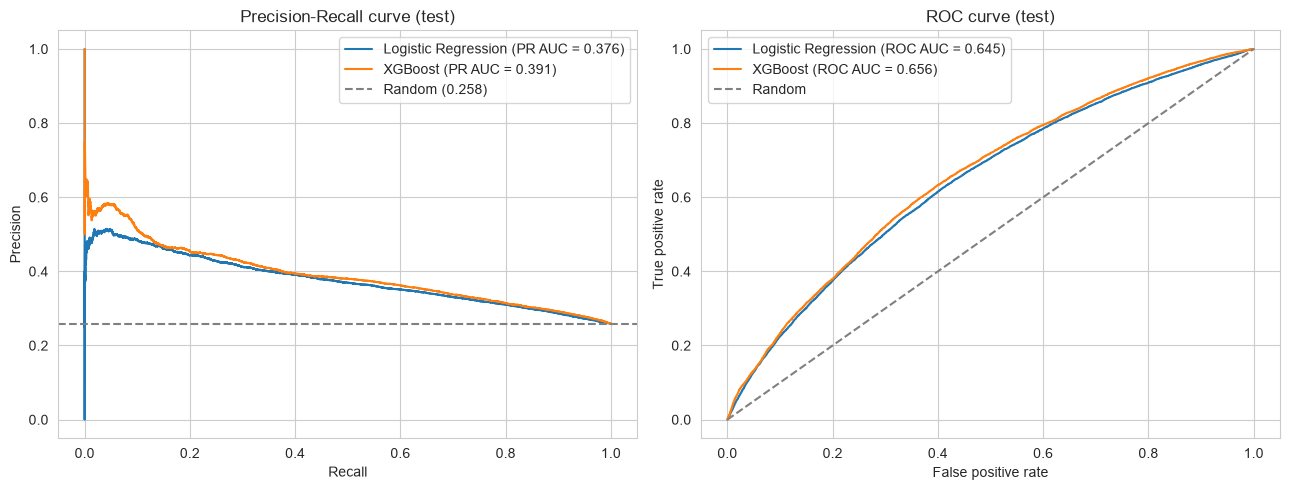

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, prob in [("Logistic Regression", test_prob_lr), ("XGBoost", test_prob_xgb)]:
    precision, recall, _ = precision_recall_curve(y_test, prob)
    axes[0].plot(recall, precision, label=f"{name} (PR AUC = {average_precision_score(y_test, prob):.3f})")
    fpr, tpr, _ = roc_curve(y_test, prob)
    axes[1].plot(fpr, tpr, label=f"{name} (ROC AUC = {roc_auc_score(y_test, prob):.3f})")

axes[0].axhline(baseline_rate, color="grey", linestyle="--", label=f"Random ({baseline_rate:.3f})")
axes[0].set_xlabel("Recall"); axes[0].set_ylabel("Precision"); axes[0].set_title("Precision-Recall curve (test)")
axes[0].legend()
axes[1].plot([0, 1], [0, 1], color="grey", linestyle="--", label="Random")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate"); axes[1].set_title("ROC curve (test)")
axes[1].legend()

plt.tight_layout()
plt.savefig("figures/pr_roc_curves.png", dpi=150)
plt.show()

### 8.1 Calibration

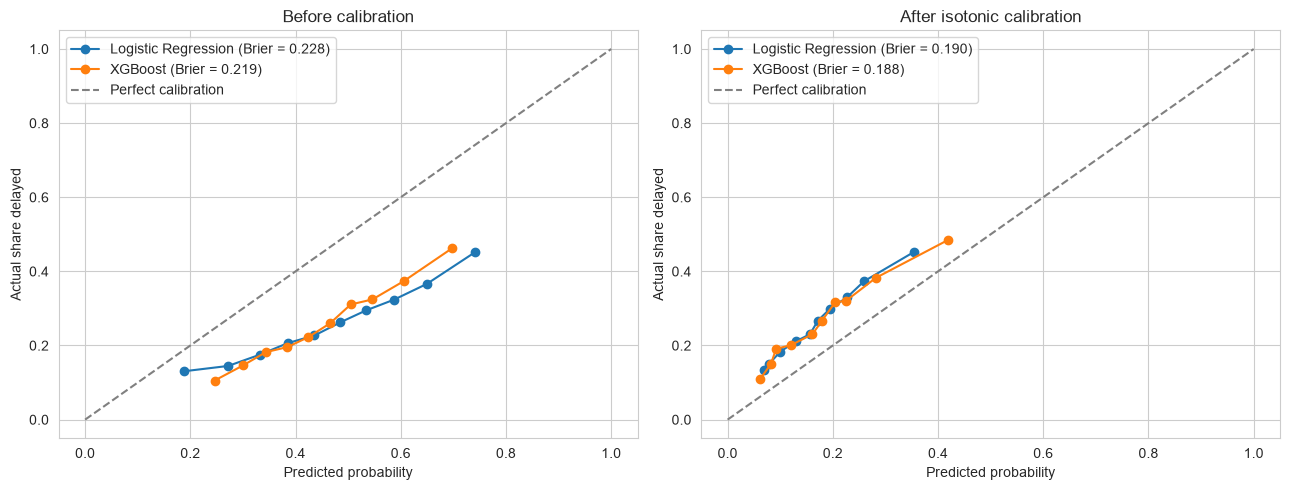

,Brier before,Brier after
Logistic Regression,0.2280,0.1899
XGBoost,0.2187,0.1880


In [22]:
from sklearn.isotonic import IsotonicRegression
from sklearn.calibration import calibration_curve

iso_lr = IsotonicRegression(out_of_bounds="clip").fit(val_prob_lr, y_val)
iso_xgb = IsotonicRegression(out_of_bounds="clip").fit(val_prob_xgb, y_val)
test_prob_lr_cal = iso_lr.predict(test_prob_lr)
test_prob_xgb_cal = iso_xgb.predict(test_prob_xgb)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, title, curves in [
    (axes[0], "Before calibration", [("Logistic Regression", test_prob_lr), ("XGBoost", test_prob_xgb)]),
    (axes[1], "After isotonic calibration", [("Logistic Regression", test_prob_lr_cal), ("XGBoost", test_prob_xgb_cal)]),
]:
    for name, prob in curves:
        frac_pos, mean_pred = calibration_curve(y_test, prob, n_bins=10, strategy="quantile")
        ax.plot(mean_pred, frac_pos, marker="o", label=f"{name} (Brier = {brier_score_loss(y_test, prob):.3f})")
    ax.plot([0, 1], [0, 1], color="grey", linestyle="--", label="Perfect calibration")
    ax.set_xlabel("Predicted probability"); ax.set_ylabel("Actual share delayed"); ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.savefig("figures/calibration.png", dpi=150)
plt.show()

pd.DataFrame({
    "Brier before": [brier_score_loss(y_test, test_prob_lr), brier_score_loss(y_test, test_prob_xgb)],
    "Brier after": [brier_score_loss(y_test, test_prob_lr_cal), brier_score_loss(y_test, test_prob_xgb_cal)],
}, index=["Logistic Regression", "XGBoost"]).round(4)

### 8.2 What does XGBoost rely on?

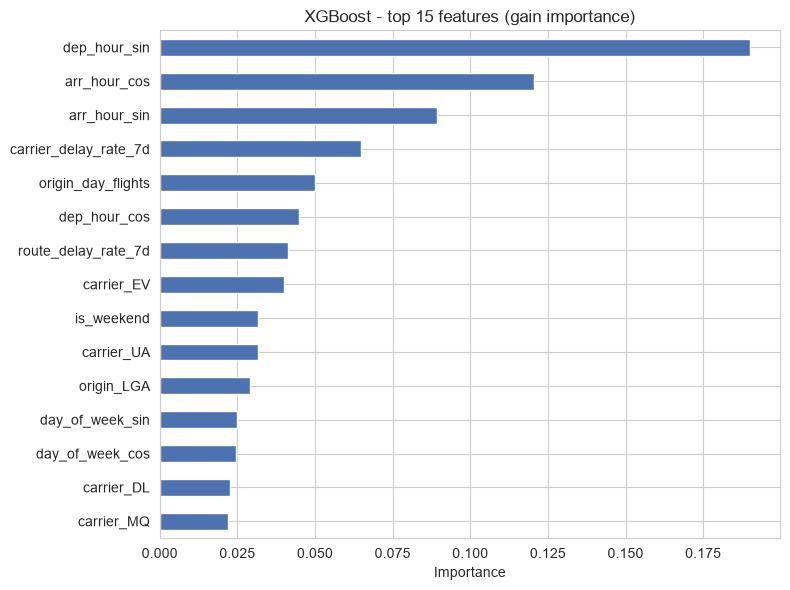

In [23]:
importance = pd.Series(xgb.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(15)

plt.figure(figsize=(8, 6))
importance.sort_values().plot(kind="barh", color="#4C72B0")
plt.title("XGBoost - top 15 features (gain importance)")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("figures/feature_importance.png", dpi=150)
plt.show()

In [24]:
# Largest Logistic Regression coefficients (features are standardised, so they are comparable)
coefs = pd.Series(log_reg[-1].coef_[0], index=X_train.columns)
coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(10).round(3)

dep_hour_sin            -0.521
origin_day_flights       0.351
route_delay_rate_7d      0.169
carrier_delay_rate_7d    0.162
dep_hour_cos             0.134
carrier_EV               0.133
origin_LGA               0.118
origin_EWR              -0.114
arr_hour_cos            -0.112
carrier_DL              -0.100
dtype: float64

### 8.3 Confusion matrix at precision ≥ 0.5

Threshold: 0.686   precision: 0.500   recall: 0.111


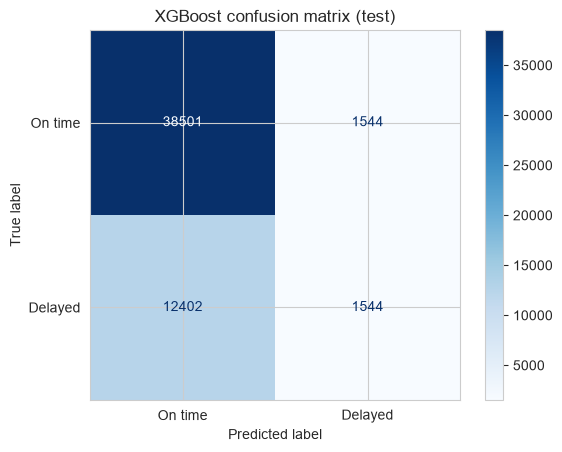

In [25]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

precision, recall, thresholds = precision_recall_curve(y_test, test_prob_xgb)
idx = np.argmax(precision[:-1] >= 0.5)       # first threshold with precision >= 0.5
threshold = thresholds[idx]
y_pred = (test_prob_xgb >= threshold).astype(int)

print(f"Threshold: {threshold:.3f}   precision: {precision[idx]:.3f}   recall: {recall[idx]:.3f}")
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["On time", "Delayed"]).plot(cmap="Blues")
plt.title("XGBoost confusion matrix (test)")
plt.savefig("figures/confusion_matrix.png", dpi=150)
plt.show()